# 2. Investigating Momentum

### Data

In this section, we empirically investigate some concerns regarding AQR's new momentum product.
On Canvas, find the data file, `data/momentum_data.xlsx`.

* The first tab contains the momentum factor as an excess return: $\tilde{r}^{\mathrm{mom}}$.
* The second tab contains returns on portfolios corresponding to scored momentum deciles.
  - $r^{\operatorname{mom}(1)}$ denotes the portfolio of stocks in the lowest momentum decile, the "losers" with the lowest past returns.
  - $r^{\operatorname{mom}(10)}$ denotes the portfolio of stocks in the highest momentum decile.
* The third tab gives portfolios sorted by momentum and size.
  - $r^{\text {momSU }}$ denotes the portfolio of small stocks in the top 3 deciles of momentum scores.
  - $r^{\text {momBD }}$ denotes the portfolio of big-stocks in the bottom 3 deciles of momentum scores.

Note that the Fama-French momentum return, $\tilde{r}^{\mathrm{mom}: \mathrm{FF}}$, given in the first tab, is constructed by $\mathrm{FF}$ as,

$$
\tilde{r}^{\mathrm{mom}: \mathrm{FF}}=\frac{1}{2}\left(r^{\mathrm{momBU}}+r^{\mathrm{momSU}}\right)-\frac{1}{2}\left(r^{\mathrm{momBD}}+r^{\mathrm{momSD}}\right)
$$

### 2.1 Is Momentum still profitable?

The excess returns of lucrative trading strategies often disappear once the strategy is well-known. The first widely-cited paper on momentum was published in 1993. Have momentum returns or risk changed since then? The AQR case takes place at the end of 2008. Have momentum returns changed in 2009-2024?

Investigate by filling out the summary statistics below for the full-sample and three sub-samples.

#### (a) 
Using the data provided, fill in Table 1 with the appropriate stats for $\tilde{r}^{\text {mom:FF }}$.

$$
\begin{equation*}
\begin{aligned}
&\text { Table 1: Long-short momentum performance. }\\
&\begin{array}{lllllll}
\hline \hline \text { Subsample } & \text { mean } & \text { vol } & \text { Sharpe } & \text { skewness } & \text { corr. to } \tilde{r}^m & \text { corr. to } \tilde{r}^v \\
\hline \hline
1927-2024 & & & & & & \\
1927-1993 & & & & & & \\
1994-2008 & & & & & & \\
2009-2024 & & & & & & \\
\hline \hline
\end{array}
\end{aligned}
\end{equation*}
$$

In [9]:
import pandas as pd 
import numpy as np 

DATA = "data/momentum_data.xlsx"
factors = pd.read_excel(DATA, sheet_name = 'factors (excess returns)', index_col = 'Date', parse_dates = True)
momentum = pd.read_excel(DATA, sheet_name = 'momentum (excess returns)', index_col = 'Date', parse_dates = True)
deciles = pd.read_excel(DATA, sheet_name = 'deciles (total returns)', index_col = 'Date', parse_dates = True)
size_sorts = pd.read_excel(DATA, sheet_name = 'size_sorts (total returns)', index_col = 'Date', parse_dates = True)
risk_free = pd.read_excel(DATA, sheet_name = 'risk-free rate', index_col = 'Date', parse_dates = True)




In [10]:
df = factors.join(momentum)   # MKT, SMB, HML, UMD in one table

#a dictionary: a list of labels, each paired with a value (start and end year)
subsamples = {
    '1927-2024': ('1927', '2024'),
    '1927-1993': ('1927', '1993'),
    '1994-2008': ('1994', '2008'),
    '2009-2024': ('2009', '2024'),
}

#r: the strategy's monthly returns (UMD)
#mkt: the market's monthly returns (MKT)
#val: the value factor's monthly returns (HML)
def summary_stats(r, mkt, val):
    return {
        'mean':      r.mean() * 12,
        'vol':       r.std() * np.sqrt(12),
        'Sharpe':    (r.mean() / r.std()) * np.sqrt(12),
        'skewness':  r.skew(),
        'corr. to MKT': r.corr(mkt),
        'corr. to HML': r.corr(val),
    }

table1 = {}
for name, (start, end) in subsamples.items():
    d = df.loc[start:end] #slice out just the years you want to look at per iteration
    table1[name] = summary_stats(d['UMD'], d['MKT'], d['HML'])

table1 = pd.DataFrame(table1).T
table1.round(4)


,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML
1927-2024,0.0739,0.1627,0.4540,-3.0673,-0.3492,-0.4098
1927-1993,0.0881,0.1605,0.5491,-3.9110,-0.3675,-0.5010
1994-2008,0.1027,0.1754,0.5858,-0.5964,-0.2402,-0.1198
2009-2024,-0.0129,0.1580,-0.0816,-2.6916,-0.3702,-0.3190


#### (b)
Has momentum changed much over time, as seen through these subsample statistics?


It appears that momentum did not disappear after it became well known in 1993. From 1994-2008, it had its highest mean of about 10.3% and sharpe ratio of 0.59. However, the mean return has shifted since the time of the case: from 2009-2024, the mean excess return and sharpe were negative, and close to zero. Momentum earned little to nothing in that period. 

Volatility has stayed relatively stable in every subsample, and skewness was strongly negative in most periods as well. This means that momentum is prone to rare but very large crashes. 

Correlations with the market and with value were negative in every subsample. They were weaker in 1994-2008, but stronger again after 2009. Overall, the risk and diversification properties of momentum have been consistent over time, but its average return has dropped significantly since 2009.

#### (c) 

Does this data support AQR's argument that momentum is an important piece of the ideal portfolio? What if mean returns to momentum are in actuality near zero due to transaction costs - would there still be evidence here that momentum is valuable?

Over the sample, the data does support AQR's argument. Over the whole sample, momentum earned a 7.4% annual excess return with a sharpe ratio of 0.45, comparable to the market itself. Additionally, it was negatively correlated with both the market and value. So, even if transaction costs brought momentum's mean return close to zero, there is still evidence for momentum's value. The negative correlations suggest an argument that it could function for diversification and reduce the overall risk of the portfolio. The main concern might be momentum's large negative skewness. Namely, momentum has rare but severe crashes. Combined with a near-zero mean return, this means investors should not rely too heavily on momentum because it poses a potentially large risk with small consistent returns. 

### 2.2. Whether a long-only implementation of momentum is valuable.

Construct your own long-only implementation:

$$\tilde{r}^{momU:FF} = \frac{1}{2} (\tilde{r}^{momBU} + \tilde{r}^{momSU}) − r^f $$

Note that this is following the FF approach of treating big and small stocks separately. This would be very similar to a scaled version of,

$$\tilde{r}^{momU} = \frac{1}{3} (\tilde{r}^{mom(8)} + \tilde{r}^{mom(9)} + \tilde{r}^{mom(10)}) − r^f $$

For the question below, use the FF-style $\tilde{r}^{momU:FF}_t$

#### (a) 

Fill out Table 2 for the data in the period 1994-2024.

$$
\begin{equation*}
\begin{aligned}
&\text { Table 2: Long-only momentum performance. }\\
&\begin{array}{lllllll}
\hline \hline \text { 1994-2024 } & \text { mean } & \text { vol } & \text { Sharpe } & \text { skew } & \text { corr. to } \tilde{r}^m & \text { corr. to } \tilde{r}^v \\
\hline \hline \text { Long-and-short, }\left(\tilde{r}^{\text {mom:FF }}\right) & & & & & & \\
\text { Long-only }\left(\tilde{r}^{\text {momU:FF }}\right) & & & & & & \\
\hline \hline
\end{array}
\end{aligned}
\end{equation*}
$$

In [11]:
#size_sorts (total returns): stocks split into piles by size (small or big company)
# and by momentum (losers, middle, winners)
# add the size-sorted portfolios and risk-free rate to the table, keep 1994-2024
df2 = df.join(size_sorts).join(risk_free).loc['1994':'2024']

# long-only momentum: half big winners + half small winners, minus risk-free
df2['momU_FF'] = 0.5 * (df2['BIG HiPRIOR'] + df2['SMALL HiPRIOR']) - df2['RF']

table2 = pd.DataFrame({
    'Long-and-short (mom:FF)': summary_stats(df2['UMD'],     df2['MKT'], df2['HML']),
    'Long-only (momU:FF)':     summary_stats(df2['momU_FF'], df2['MKT'], df2['HML']),
}).T

table2.round(4)


,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML
Long-and-short (mom:FF),0.0431,0.1672,0.2575,-1.461,-0.3105,-0.2104
Long-only (momU:FF),0.1161,0.1780,0.6524,-0.442,0.9040,-0.1163


#### (b)  
Is long-only momentum as attractive as long-short momentum with respect to mean, volatility, and Sharpe Ratio?

Just looking at the table, long-only looks better. It has a higher mean, similar vol, and a much higher sharpe. However, we can see that long-only has a 0.9 correlation to the market, which suggests that the strategy moves with the stock market. So, we cannot decisively say that its high mean and sharpe is due to beating the market or doing something 'well', rather than just mimicking the market. 

#### (c) 
Is long-only momentum as diversifying as long-short momentum with respect to market and value premia?

No. Correlation to the market goes from -0.31 with long-and-short all the way up to +0.90 for long-only. Long-only momentum moves almost exactly with the market. The correlation with value stays slighly negative, but is much weaker than for long-short. In 2.1(c), we discussed how momentum is valuable even with a near-zero mean due to its negative correlation with the market. However, long-only appears to lack that benefit. So, if an investor or portfolio already owns the market, adding long-only momentum is really just adding more of the same thing, and thus, is not a diversifying factor.

#### (d) 
Show a plot of the cumulative product of $1+\tilde{r}^{\text {mom:FF }}$ and $1+\tilde{r}^{\text {momU:FF }}$ over the 1994-2024 subsample.

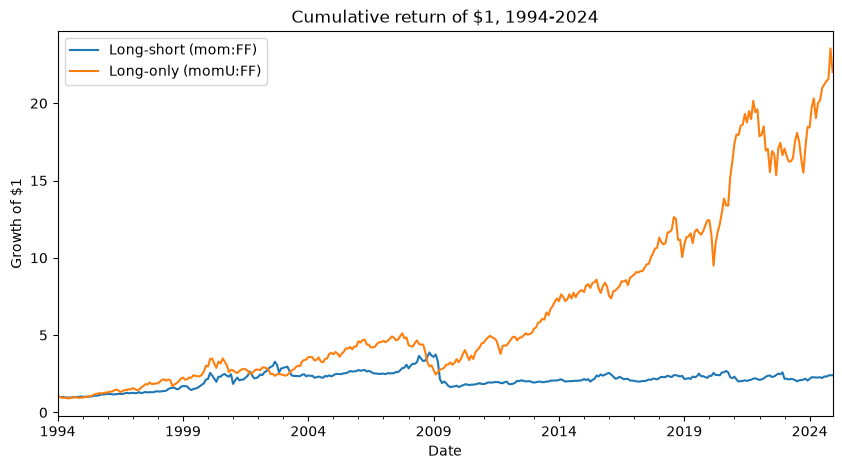

In [12]:
import matplotlib.pyplot as plt

cum = (1 + df2[['UMD', 'momU_FF']]).cumprod()
cum.columns = ['Long-short (mom:FF)', 'Long-only (momU:FF)']

cum.plot(figsize=(10, 5), title='Cumulative return of $1, 1994-2024')
plt.ylabel('Growth of $1')
plt.show()


The long-only line ends much higher, but it dips whenever the market dips (dot-com crash in 2000-2002, 2008 crisis, 2020 covid). The long-short line behaves differently: it rose during the 2008 crash, then collapsed in 2009. The two strategies get hurt at different times. Long-only suffers in market crashes, while long-short suffers in sharp rebounds after crashes. 

Long-only earns good returns, but much of that is just market exposure. It does not deliver the diversification that makes momentum special. It is not a substitute for long-short momentum. 

### 2.3. 
Is momentum just data mining, or is it a robust strategy?

Assess how sensitive the threshold for the “winners” and “losers” is in the results. Specifically, we compare three constructions:

- long the top 1 decile and short the bottom 1 deciles:

$$ \tilde{r}^{momD1} = r^{mom(10)} - r^{mom(1)}$$

- long the top 3 deciles and short the bottom 3 deciles:

$$ 
\begin{aligned}
\tilde{r}^{momD3} &= \frac{1}{3}(r^{mom(8)} + r^{mom(9)} + r^{mom(10)}) - \frac{1}{3} (r^{mom(3)} + r^{mom(2)} + r^{mom(1)})\\
&= \frac{1}{3}\sum_{k = 8}^{10} r^{mom(k)} - \frac{1}{3}\sum_{k = 1}^{3} r^{mom(k)} 
\end{aligned}$$

- long the top 5 deciles and short the bottom 5 decile:

$$ \tilde{r}^{momD5} = \frac{1}{5}\sum_{k = 6}^{10} r^{mom(k)} - \frac{1}{5}\sum_{k = 1}^{5} r^{mom(k)} $$

#### (a) 
Compare all three constructions by filling out the stats in the table below for the period 1994-2024.

$$
\begin{equation}
\begin{aligned}
&\text { Table 3: Robustness of momentum construction. }\\
&\begin{array}{lllllll}
\hline \hline \text { 1994-2024 } & \text { mean } & \text { vol } & \text { Sharpe } & \text { skewness } & \text { corr. to } \tilde{r}^m & \text { corr. to } \tilde{r}^v \\
\hline \hline \tilde{r}^{\text {momD1 }} & & & & & & \\
\tilde{r}^{\text {momD3 }} & & & & & & \\
\tilde{r}^{\text {momD5 }} & & & & & & \\
\hline \hline
\end{array}
\end{aligned}
\end{equation}
$$

In [13]:
# deciles (total returns): stocks sorted into 10 piles by past return
# column 0 = 'Lo PRIOR' (decile 1, losers) ... column 9 = 'Hi PRIOR' (decile 10, winners)
# risk-free cancels out in long-short, so total returns are fine here
df3 = df.join(deciles).loc['1994':'2024']
dec = df3[deciles.columns]

# long top n deciles, short bottom n deciles (equal-weighted within each leg)
def momD(n):
    return dec.iloc[:, -n:].mean(axis=1) - dec.iloc[:, :n].mean(axis=1)

df3['momD1'] = momD(1)
df3['momD3'] = momD(3)
df3['momD5'] = momD(5)

table3 = pd.DataFrame({
    name: summary_stats(df3[name], df3['MKT'], df3['HML'])
    for name in ['momD1', 'momD3', 'momD5']
}).T

table3.round(4)


,mean,vol,Sharpe,skewness,corr. to MKT,corr. to HML
momD1,0.0810,0.2996,0.2703,-1.3012,-0.3242,-0.2375
momD3,0.0297,0.1937,0.1535,-1.3411,-0.3632,-0.2121
momD5,0.0173,0.1343,0.1285,-1.4215,-0.3544,-0.2087


#### (b) 
Do the tradeoffs between the 1-decile, 3-decile, and 5-decile constructions line up with the theoretical tradeoffs we discussed in the lecture?

From the lecture, momentum relies on a very small autocorrelation in returns, which is profitable in two ways:

**Trading the extreme winners and losers.** A small autocorrelation multiplied by a large past return gives a sizeable expected return next period. The 1-decile construction does this most aggressively, and it has the highest mean at 8.1%. The 5-decile construction includes stocks near the middle of the distribution. Their past returns are small, so their predicted returns are small too, and the mean drops to 1.7%.

**Holding many stocks.** Each stock's autoregression has a tiny R², so the strategy only works by playing the odds across many stocks at once, which diversifies away idiosyncratic risk. The 5-decile construction holds the most stocks and has the lowest volatility at 13.4%. The 1-decile construction holds the fewest and has the highest volatility at 30.0%.


#### (c) 
Should AQR's retail product consider using a 1-decile or 5-decile construction?

From this analysis, probably neither. Instead, the middle construction of 3-deciles is probably the most sensible choice for a retail product. The 3-decile construction balances the two lecture principles: it trades stocks that are extreme enough to carry a meaningful signal, while still holding enough of them to diversify idiosyncratic risk and keep trading costs manageable. This is also the cutoff used in the Fama-French construction. In addition, AQR's interest in larger and more liquid stocks pushes toward a broader portfolio than the 1-decile version.

#### (d) 
Does $\tilde{r}^{\text {momD3 }}$ have similar stats to the Fama-French construction in (1). Recall that construction is also a 3-decile, long-short construction, but it is segmented for small and large stocks. Compare the middle row of Table 3 with the top row of Table 2.

The two are similar in risk profile, but not in performance. Both have strong negative skewness and are negatively correlated with the market and with value by about the same amount. The crash risk and diversification benefits of momentum show up in both constructions.

However, The Fama-French version earns a higher mean (4.31% vs. 2.97%) with lower volatility (16.7% vs. 19.4%). As a result, its Sharpe ratio is about 70% higher (0.26 vs. 0.15).

The difference comes from the size segmentation. The decile portfolios sort all stocks together and are value-weighted, so they are dominated by large stocks. The Fama-French construction puts half its weight on small stocks no matter how large big stocks are by market value, and momentum is much stronger among small stocks. Over 1994-2024, small-stock momentum earned 6.1% per year (Sharpe 0.36), while big-stock momentum earned only 2.5% (Sharpe 0.14). The momD3 mean of 2.97% sits close to the big-stock number.

The segmentation also lowers volatility. Small-stock and big-stock momentum have a correlation of about 0.81, not 1, so averaging them gives some diversification. The Fama-French volatility of 16.7% is lower than either leg on its own (16.9% and 18.2%).

### 2.4. 
Does implementing momentum require trading lots of small stocks-- thus causing even larger trading costs?

For regulatory and liquidity reasons, AQR is particularly interested in using larger stocks for their momentum baskets. (Though they will launch one product that focuses on medium-sized stocks.)

Use the data provided on both small-stock “winners”, $r^{momSU}$, and small-stock “losers”, $r^{momSD}$, to construct a small-stock momentum portfolio,

$$ r^{momS}_t = r^{momSU}_t - r^{momSD}_t $$

Similarly, use the data provided to construct a big-stock momentum portfolio,

$$ r^{momB}_t = r^{momBU}_t − r^{momBD}_t $$

#### (a) 
Fill out Table 4 over the sample 1994-2024.

$$
\begin{equation*}
\begin{aligned}
&\text { Table 4: Momentum of small and big stocks. }\\
&\begin{array}{llllll}
\hline \hline \text { 1994-2024 } & \text { mean } & \text { vol } & \text { Sharpe } & \text { skewness } & \text { corr. to } \tilde{r}^m \\
\hline \hline \text { All stocks, } \tilde{r}^{\text {mom:FF }} & & & & & \\
\text { Small stocks } r_t^{\text {mom } S} & & & & & \\
\text { Large stocks } r_t^{\text {mom } B} & & & & & \\
\hline
\end{array}
\end{aligned}
\end{equation*}
$$

In [ ]:
df2['momS'] = df2['SMALL HiPRIOR'] - df2['SMALL LoPRIOR']
df2['momB'] = df2['BIG HiPRIOR'] - df2['BIG LoPRIOR']


table4 = pd.DataFrame({
    label: summary_stats(df2[col], df2['MKT'], df2['HML'])
    for label, col in {
        'All Stocks': 'UMD',
        'Small Stocks': 'momS',
        'Large Stocks': 'momB'
    }.items()
}).T

table4 = table4.drop(columns = ['corr. to HML'])
table4.round(4)


,mean,vol,Sharpe,skewness,corr. to MKT
All Stocks,0.0431,0.1672,0.2575,-1.4610,-0.3105
Small Stocks,0.0614,0.1691,0.3631,-1.8042,-0.3102
Large Stocks,0.0246,0.1823,0.1351,-0.8745,-0.2819


#### (b) 
Is the attractiveness of the momentum strategy mostly driven by the small stocks? That is, does a momentum strategy in large stocks still deliver excess returns at comparable risk?

Momentum seems to be mostly driven by small stocks since they have a higher average return of 6.14% compared to 2.46% for large stocks, while also having slightly lower volatility. This explains why small stocks have a much higher Sharpe ratio. Large stocks still have positive excess returns, but their risk adjusted performance is much worse. However, small stocks do have more negative skewness, meaning they are more exposed to extreme losses.

### 2.5. 
In conclusion, what is your assessment of the AQR retail product? Is it capturing the important features of the Fama-French construction of momentum? Would you suggest any modifications?

I think AQR's retail product is still attractive because it allows investors to benefit from momentum, but it does not fully capture the benefits of the Fama French strategy. Since the fund is long only, it has a much higher correlation with the market and loses a lot of the diversification benefits that come from shorting losers. However, keeping it long only makes sense given the restrictions on mutual funds. I would suggest including more small stocks since our results showed that they have stronger momentum returns, but still balancing that with liquidity and trading costs. Overall, I think it is a reasonable way to offer momentum to retail investors, even if it doesn't fully replicate the traditional strategy.